# XGBoost modeluaren entrenamendua

### 1 Liburutegien inportazioa eta karga

In [24]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path("../scoring").resolve()))  # cnc_ml eta app inportatu ahal izateko

import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import (
    average_precision_score,
    classification_report,
    confusion_matrix,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier
from cnc_ml.columns import FAILURE_SUBTYPES, MACHINE_TYPES, RAW_FEATURES, TARGET
from cnc_ml.pipeline import build_pipeline
from app.services.model import FAILURE_THRESHOLD
import importlib
import app.services.model as m
importlib.reload(m)

df = pd.read_csv("../data/ai4i2020_train.csv")
print( df.shape)




(8000, 13)


### 2. Datuen azterketa

In [25]:
#Sarrerako zutabeak prestatu

delete_cols = [
    "machine_id",
    "failure_TWF", "failure_HDF", "failure_PWF", "failure_OSF", "failure_RNF",
]

X = df.drop(columns=delete_cols + [TARGET])
y = df[TARGET]

# XGBoost-ek zenbakiak bakarrik ulertzen ditu. machine_type testua da (L, M, H) =  kalitate baxua, ertaina, altua. Ordena naturala duenez, 0, 1, 2 bihurtzen dugu.
X["machine_type"] = X["machine_type"].map({"L": 0, "M": 1, "H": 2})

# Feature engineering: zentzu fisikoa duten zutabe berriak sortu.

X["temp_diff_K"] = X["process_temp_K"] - X["air_temp_K"]            # bero-xahutzea
X["power_W"] = X["torque_Nm"] * X["rpm"] * 2 * math.pi / 60         # potentzia mekanikoa
X["wear_torque"] = X["tool_wear_min"] * X["torque_Nm"]              # gainkarga

print("\nEreduak erabiliko dituen feature-ak:", list(X.columns))


Ereduak erabiliko dituen feature-ak: ['machine_type', 'air_temp_K', 'process_temp_K', 'rpm', 'torque_Nm', 'tool_wear_min', 'temp_diff_K', 'power_W', 'wear_torque']


### 3. TRAIN / BALIOZTAPENA / TEST ZATITAN

In [26]:
#- train:        ereduak honekin ikasten du
# - balioztapena: noiz gelditu erabakitzeko (early stopping)
# - test:         AMAIERAN bakarrik erabiltzen da, benetako nota jakiteko. Inoiz ez doitzeko.
#
# stratify=y   -> hutsegiteen % bera mantentzen du zati bakoitzean (garrantzitsua hutsegite gutxirekin)
# random_state -> emaitza beti bera izan dadin eta errepika daitekeen
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.20, stratify=y_temp, random_state=42
)
print(f"\nTrain: {len(X_train)}  |  Balioztapena: {len(X_val)}  |  Test: {len(X_test)}")




Train: 5120  |  Balioztapena: 1280  |  Test: 1600


### 4.EREDUA SORTU 

In [27]:
# XGBoost-en ideia: erabaki-zuhaitz txiki asko eraikitzen ditu, bata bestearen atzetik. Zuhaitz berri bakoitza
# aurrekoen akatsak zuzentzen saiatzen da ("boosting"). Azken iragarpena guztien batura da.

hutsegite_pisua = (y_train == 0).sum() / (y_train == 1).sum()

eredua = XGBClassifier(
    n_estimators=1000,        # zuhaitz kopuru MAXIMOA (early stopping-ek lehenago geldituko du)
    learning_rate=0.05,       # zuhaitz bakoitzak zenbat ekartzen duen. Baxua = motelagoa baina finagoa
    max_depth=4,              # zuhaitz bakoitzaren sakonera. Gehiago = konplexuagoa (gaindoitze-arriskua)
    min_child_weight=1,       # hosto batean gutxieneko "pisua"; igotzeak eredua kontserbadoreagoa egiten du
    subsample=0.8,            # zuhaitz bakoitzak errenkaden % 80 bakarrik ikusten du (gaindoitzea murrizten du)
    colsample_bytree=0.8,     # eta zutabeen % 80 bakarrik
    scale_pos_weight=hutsegite_pisua,   # klaseen desoreka konpentsatzen du
    eval_metric="aucpr",      # zaindu beharreko metrika: precision-recall kurbaren azpiko area (ona desorekarekin)
    early_stopping_rounds=50, # balioztapenean 50 zuhaitz jarraian hobetzen ez badu, gelditu
    random_state=42,
    n_jobs=-1,                # ordenagailuaren nukleo guztiak erabili
)

### 5. ENTRENATU

In [28]:
# eval_set: early stopping-erako zaintzen dituen balioztapen-datuak.
# verbose=100: 100 zuhaitzetik behin nola doan inprimatzen du.
eredua.fit(
    X_train, y_train,
    eval_set=[(X_val, y_val)],
    verbose=100,
)
print(f"\nZuhaitz kopuru onena: {eredua.best_iteration + 1}")

[0]	validation_0-aucpr:0.55003
[100]	validation_0-aucpr:0.88791
[108]	validation_0-aucpr:0.88566

Zuhaitz kopuru onena: 59


### 6.TESTEAREKIN EBALUATU

In [29]:
# predict_proba-k klase bakoitzaren probabilitatea itzultzen du; [:, 1] = hutsegite-probabilitatea
hutsegite_prob = eredua.predict_proba(X_test)[:, 1]

# ATALASEAK (umbral) erabakitzen du zein probabilitatetik aurrera esaten dugun "huts egingo du".
# 0.5 da ohikoa, baina hutsegite bat ez detektatzea garestia bada (makina hautsita),
# komeni da jaistea: hutsegite gehiago detektatzen dituzu, alarma faltsu gehiagoren truke.
# (Horregatik jaitsi zenuten 0.15era zuen proiektuan.)
ATALASEA = 0.15
iragarpena = (hutsegite_prob > ATALASEA).astype(int)

print(f"\nROC-AUC: {roc_auc_score(y_test, hutsegite_prob):.3f}   (1 = perfektua, 0.5 = zoria)")

print(f"\nTxostena {ATALASEA} atalasearekin:")
# precision: ematen dituen alarmetatik, zenbat ziren benetako hutsegiteak
# recall:    benetako hutsegiteetatik, zenbat detektatzen dituen  <- hemen garrantzitsuena
print(classification_report(y_test, iragarpena, target_names=["OK", "Hutsegitea"]))

# Nahasmen-matrizea:
#                     OK iragarri    Hutsegitea iragarri
#   benetan OK         [  TN              FP  ]   FP = alarma faltsua
#   benetan hutsegitea [  FN              TP  ]   FN = detektatu GABEKO hutsegitea (txarrena)
print("Nahasmen-matrizea:")
print(confusion_matrix(y_test, iragarpena))


ROC-AUC: 0.980   (1 = perfektua, 0.5 = zoria)

Txostena 0.15 atalasearekin:
              precision    recall  f1-score   support

          OK       1.00      0.87      0.93      1546
  Hutsegitea       0.20      0.96      0.33        54

    accuracy                           0.87      1600
   macro avg       0.60      0.91      0.63      1600
weighted avg       0.97      0.87      0.91      1600

Nahasmen-matrizea:
[[1339  207]
 [   2   52]]


### 7.GRAFIKOAK ETA ATALSAE PROBAK

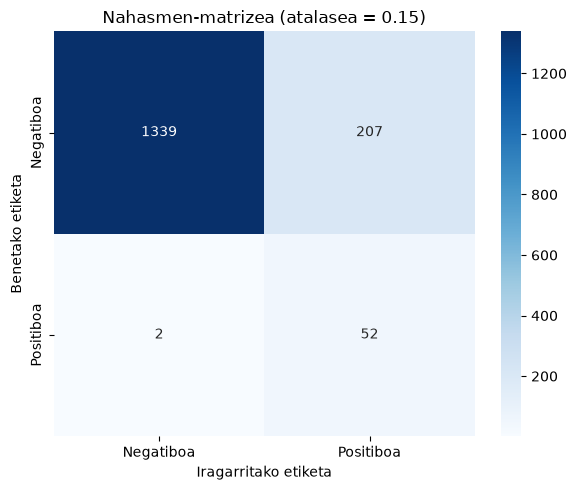

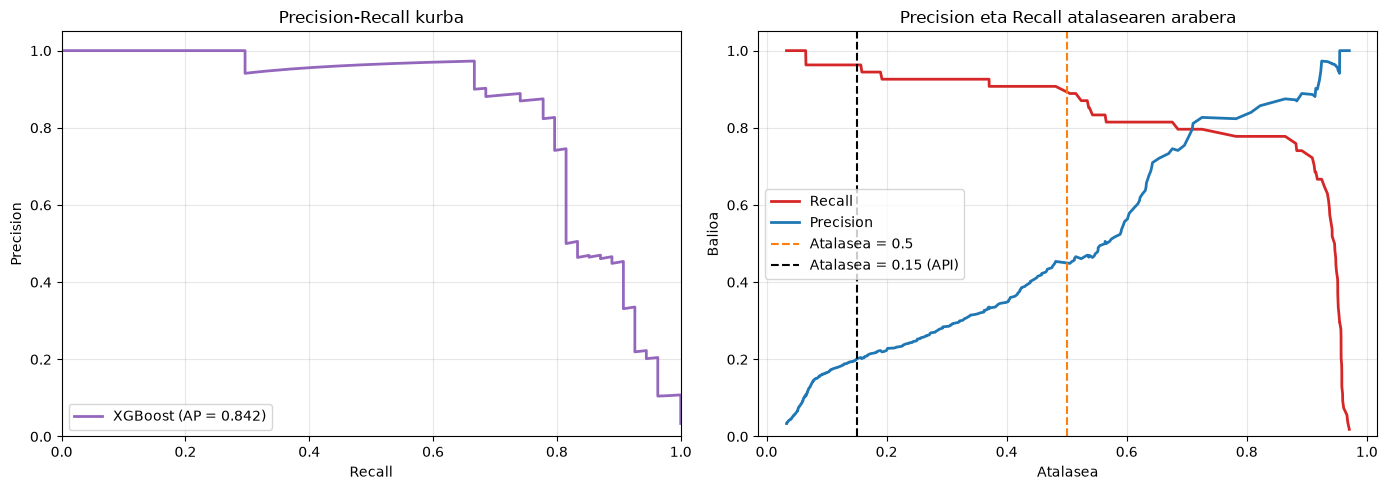


Atalasea | Negatibo faltsuak | Positibo faltsuak | Recall | Precision
----------------------------------------------------------------------
0.5      |                 6 |                59 |   0.89 |      0.45
0.45     |                 5 |                70 |   0.91 |      0.41
0.4      |                 5 |                91 |   0.91 |      0.35
0.35     |                 4 |               107 |   0.93 |      0.32
0.3      |                 4 |               125 |   0.93 |      0.29
0.25     |                 4 |               151 |   0.93 |      0.25
0.2      |                 4 |               174 |   0.93 |      0.22
0.15     |                 2 |               207 |   0.96 |      0.20
0.1      |                 2 |               263 |   0.96 |      0.17

Kostu txikiena: 51,700 € (atalasea = 0.48)
Eredurik gabe (hutsegite guztiak FN): 270,000 €


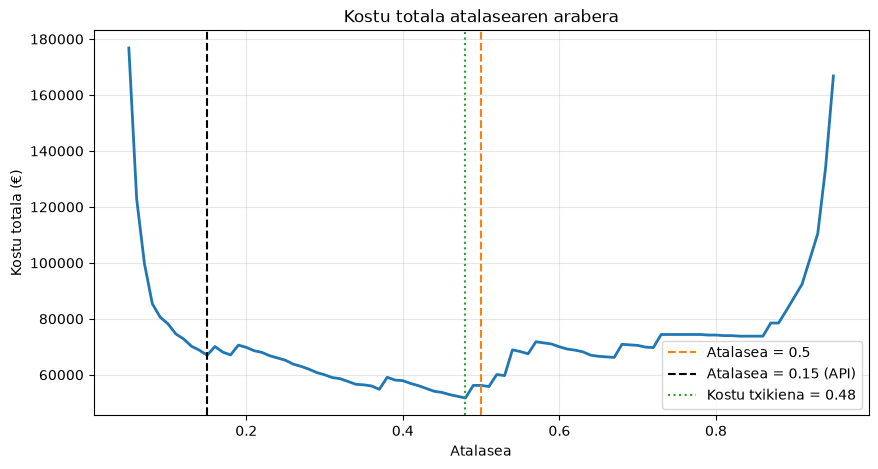

In [31]:

# Hemendik aurrera TEST zatiarekin lan egiten da (6. atalean bezala).
# Izen laburrak, grafikoen kodea irakurterrazagoa izan dadin:
y_eval = y_test             # benetako etiketak
y_proba = hutsegite_prob    # ereduaren hutsegite-probabilitatea
y_pred = iragarpena         # ATALASEA-rekin lortutako iragarpena (0/1)


# --- 8.1 Nahasmen-matrizea (heatmap) ---
nahasketa = confusion_matrix(y_eval, y_pred)
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(nahasketa, annot=True, fmt="d", cmap="Blues", ax=ax,
            xticklabels=["Negatiboa", "Positiboa"],
            yticklabels=["Negatiboa", "Positiboa"])
ax.set_ylabel("Benetako etiketa")
ax.set_xlabel("Iragarritako etiketa")
ax.set_title(f"Nahasmen-matrizea (atalasea = {ATALASEA})")
plt.tight_layout()
plt.show()


# --- 8.2 Precision vs Recall ---
precision, recall, atalase_kurba = precision_recall_curve(y_eval, y_proba)
ap = average_precision_score(y_eval, y_proba)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))   # 1 errenkada, 2 grafiko

# 1. grafikoa: precision-recall kurba
ax = axes[0]
ax.plot(recall, precision, lw=2, color="tab:purple", label=f"XGBoost (AP = {ap:.3f})")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Precision-Recall kurba")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.05)
ax.legend()
ax.grid(alpha=0.3)

# 2. grafikoa: precision eta recall atalasearen arabera
# (precision eta recall-ek atalaseak baino balio 1 gehiago dute, horregatik [:-1])
ax = axes[1]
ax.plot(atalase_kurba, recall[:-1], lw=2, color="tab:red", label="Recall")
ax.plot(atalase_kurba, precision[:-1], lw=2, color="tab:blue", label="Precision")
ax.axvline(0.5, color="tab:orange", ls="--", label="Atalasea = 0.5")
ax.axvline(ATALASEA, color="black", ls="--", label=f"Atalasea = {ATALASEA} (API)")
ax.set_xlabel("Atalasea")
ax.set_ylabel("Balioa")
ax.set_title("Precision eta Recall atalasearen arabera")
ax.set_ylim(0, 1.05)
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# --- 8.4 Atalase desberdinekin proba (taula) ---
print("\nAtalasea | Negatibo faltsuak | Positibo faltsuak | Recall | Precision")
print("-" * 70)
for atalasea in [0.5, 0.45, 0.4, 0.35, 0.3, 0.25, 0.2, 0.15, 0.1]:
    pred = (y_proba > atalasea).astype(int)
    fn = ((pred == 0) & (y_eval == 1)).sum()
    fp = ((pred == 1) & (y_eval == 0)).sum()
    rec = recall_score(y_eval, pred)
    prec = precision_score(y_eval, pred, zero_division=0)
    print(f"{atalasea:<8} | {fn:>17} | {fp:>17} | {rec:>6.2f} | {prec:>9.2f}")


# --- 8.3 Kostua atalasearen arabera ---
# Kostu-taula ofiziala (€): FN = detektatu gabeko hutsegitea, FP = alarma faltsua...
C_FN, C_FP, C_TP, C_TN = 5000, 200, 300, 0

atalaseak = np.round(np.arange(0.05, 0.96, 0.01), 2)
kostuak = []
for u in atalaseak:
    pred = (y_proba > u).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_eval, pred).ravel()
    kostuak.append(C_FN * fn + C_FP * fp + C_TP * tp + C_TN * tn)

onena = atalaseak[np.argmin(kostuak)]
print(f"\nKostu txikiena: {min(kostuak):,} € (atalasea = {onena})")
print(f"Eredurik gabe (hutsegite guztiak FN): {C_FN * y_eval.sum():,} €")

plt.figure(figsize=(10, 5))
plt.plot(atalaseak, kostuak, lw=2)
plt.axvline(0.5, color="tab:orange", ls="--", label="Atalasea = 0.5")
plt.axvline(ATALASEA, color="black", ls="--", label=f"Atalasea = {ATALASEA} (API)")
plt.axvline(onena, color="tab:green", ls=":", label=f"Kostu txikiena = {onena}")
plt.xlabel("Atalasea")
plt.ylabel("Kostu totala (€)")
plt.title("Kostu totala atalasearen arabera")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

